In [1]:
# ==========================================
# TAHAP 0-3: Akuisisi, Pembersihan, dan Penyelarasan Data
# ==========================================
from google.colab import drive
import os
import pandas as pd
import numpy as np

# Mounting Drive
drive.mount('/content/drive')
folder_path = '/content/drive/MyDrive/Tugas Akhir/Dataset'

# Memuat dataset
df_nh = pd.read_csv(os.path.join(folder_path, "NH.Ts+dSST.csv"), skiprows=1)
df_sh = pd.read_csv(os.path.join(folder_path, "SH.Ts+dSST.csv"), skiprows=1)
df_co2 = pd.read_csv(os.path.join(folder_path, "co2_mm_gl.csv"), comment='#')

# Konversi dan Drop NaN
df_nh['Temp_NH'] = pd.to_numeric(df_nh['J-D'], errors='coerce')
df_sh['Temp_SH'] = pd.to_numeric(df_sh['J-D'], errors='coerce')
df_nh_annual = df_nh[['Year', 'Temp_NH']].dropna()
df_sh_annual = df_sh[['Year', 'Temp_SH']].dropna()

# Agregasi CO2 ke rata-rata tahunan
df_co2_annual = df_co2.groupby('year')['average'].mean().reset_index()
df_co2_annual.rename(columns={'year': 'Year', 'average': 'CO2_ppm'}, inplace=True)

# Penyelarasan Time-Series (Inner Join)
df_merged = pd.merge(df_co2_annual, df_nh_annual, on='Year', how='inner')
df_merged = pd.merge(df_merged, df_sh_annual, on='Year', how='inner')

Mounted at /content/drive


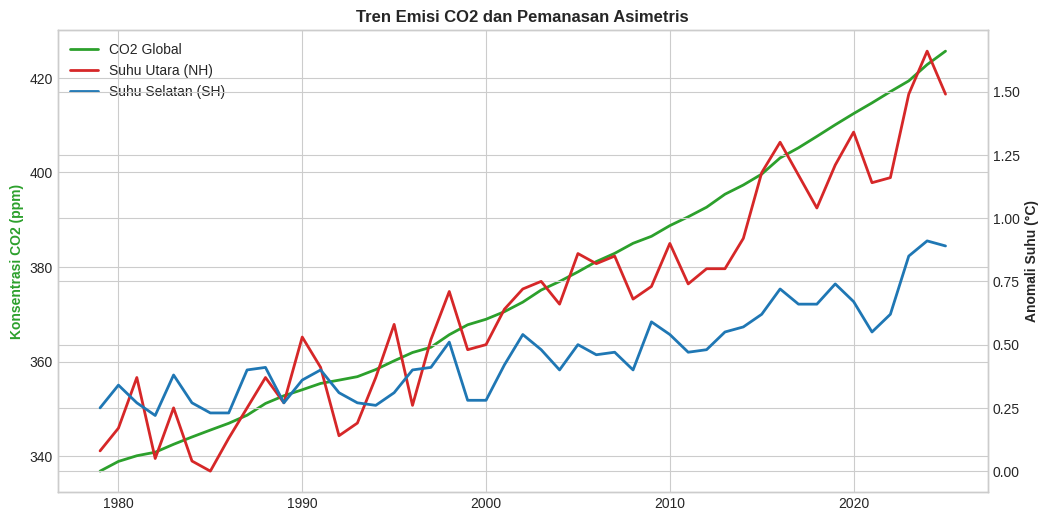

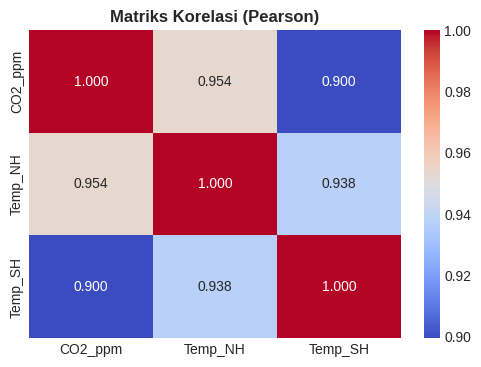

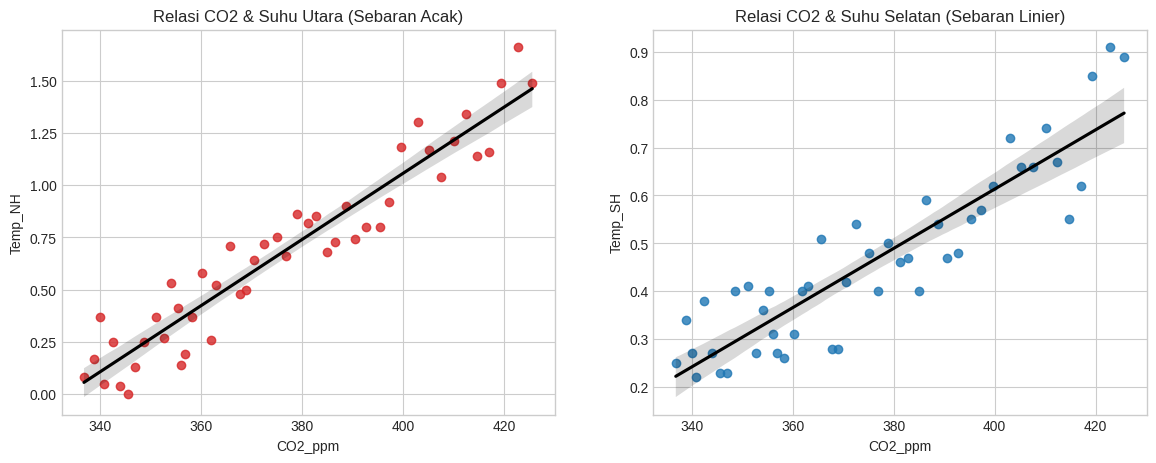

In [2]:
# ==========================================
# TAHAP 4-5: Visualisasi Tren, Distribusi, dan Regresi
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('seaborn-v0_8-whitegrid')

# 1. Tren Makro Pemanasan
fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(df_merged['Year'], df_merged['CO2_ppm'], color='tab:green', linewidth=2, label='CO2 Global')
ax1.set_ylabel('Konsentrasi CO2 (ppm)', color='tab:green', fontweight='bold')
ax2 = ax1.twinx()
ax2.plot(df_merged['Year'], df_merged['Temp_NH'], color='tab:red', linewidth=2, label='Suhu Utara (NH)')
ax2.plot(df_merged['Year'], df_merged['Temp_SH'], color='tab:blue', linewidth=2, label='Suhu Selatan (SH)')
ax2.set_ylabel('Anomali Suhu (°C)', fontweight='bold')
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')
plt.title('Tren Emisi CO2 dan Pemanasan Asimetris', fontweight='bold')
plt.show()

# 2. Matriks Korelasi
plt.figure(figsize=(6, 4))
sns.heatmap(df_merged[['CO2_ppm', 'Temp_NH', 'Temp_SH']].corr(), annot=True, cmap='coolwarm', fmt=".3f")
plt.title('Matriks Korelasi (Pearson)', fontweight='bold')
plt.show()

# 3. Scatter Plot Regresi (Bukti Linieritas)
fig, (ax3, ax4) = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(x=df_merged['CO2_ppm'], y=df_merged['Temp_NH'], ax=ax3, color='tab:red', line_kws={'color':'black'})
ax3.set_title('Relasi CO2 & Suhu Utara (Sebaran Acak)')
sns.regplot(x=df_merged['CO2_ppm'], y=df_merged['Temp_SH'], ax=ax4, color='tab:blue', line_kws={'color':'black'})
ax4.set_title('Relasi CO2 & Suhu Selatan (Sebaran Linier)')
plt.show()

In [3]:
# ==========================================
# TAHAP 6-7: Stasioneritas, Differencing, dan Granger Causality
# ==========================================
from statsmodels.tsa.stattools import adfuller, grangercausalitytests

# Second-Order Differencing khusus CO2
df_diff = df_merged[['CO2_ppm', 'Temp_NH', 'Temp_SH']].diff().dropna()
df_diff['CO2_ppm_2nd'] = df_diff['CO2_ppm'].diff()
df_diff = df_diff.dropna()

print("P-Value ADF CO2 (2nd-Order):", adfuller(df_diff['CO2_ppm_2nd'], result_object=False)[1])
print("P-Value ADF Suhu NH (1st-Order):", adfuller(df_diff['Temp_NH'], result_object=False)[1])
print("P-Value ADF Suhu SH (1st-Order):", adfuller(df_diff['Temp_SH'], result_object=False)[1])

print("\n--- Uji Granger Causality ---")

# 1. Menghitung dan menampilkan manual untuk NH (Utara)
print("NH (Utara):")
gc_nh = grangercausalitytests(df_diff[['Temp_NH', 'CO2_ppm_2nd']], maxlag=3)
for lag in gc_nh.keys():
    # Mengambil nilai p-value dari uji ssr_ftest
    p_value = gc_nh[lag][0]['ssr_ftest'][1]
    print(f"  Lag {lag}: P-Value = {p_value:.4f}")

# 2. Menghitung dan menampilkan manual untuk SH (Selatan)
print("\nSH (Selatan):")
gc_sh = grangercausalitytests(df_diff[['Temp_SH', 'CO2_ppm_2nd']], maxlag=3)
for lag in gc_sh.keys():
    # Mengambil nilai p-value dari uji ssr_ftest
    p_value = gc_sh[lag][0]['ssr_ftest'][1]
    print(f"  Lag {lag}: P-Value = {p_value:.4f}")

P-Value ADF CO2 (2nd-Order): 4.4071022297128126e-15
P-Value ADF Suhu NH (1st-Order): 2.2904449282541243e-06
P-Value ADF Suhu SH (1st-Order): 9.892701404924682e-06

--- Uji Granger Causality ---
NH (Utara):
  Lag 1: P-Value = 0.1292
  Lag 2: P-Value = 0.4042
  Lag 3: P-Value = 0.2645

SH (Selatan):
  Lag 1: P-Value = 0.0387
  Lag 2: P-Value = 0.2129
  Lag 3: P-Value = 0.0805


In [4]:
# ==========================================
# TAHAP 8: Splitting dan Ekstraksi Fitur Sliding Window
# ==========================================
from sklearn.preprocessing import MinMaxScaler

# Mengamankan proporsi Data Latih (80%)
train_size = int(len(df_merged) * 0.8)

# Inisialisasi Scaler
scaler_nh = MinMaxScaler(feature_range=(0, 1))
scaler_sh = MinMaxScaler(feature_range=(0, 1))

# FIT SCALER HANYA PADA DATA LATIH (Menghindari Data Leakage)
scaler_nh.fit(df_merged[['CO2_ppm', 'Temp_NH']].iloc[:train_size])
scaler_sh.fit(df_merged[['CO2_ppm', 'Temp_SH']].iloc[:train_size])

# Transformasikan ke seluruh data setelah scaler mempelajari 80% data awal
data_nh = scaler_nh.transform(df_merged[['CO2_ppm', 'Temp_NH']])
data_sh = scaler_sh.transform(df_merged[['CO2_ppm', 'Temp_SH']])

# Ekstraksi Sliding Window (3 Langkah Waktu)
def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:(i + seq_length)])
        y.append(data[i + seq_length, 1])
    return np.array(X), np.array(y)

SEQ_LENGTH = 3
X_nh, y_nh = create_sequences(data_nh, SEQ_LENGTH)
X_sh, y_sh = create_sequences(data_sh, SEQ_LENGTH)

# Splitting 80:20
X_train_nh, X_test_nh = X_nh[:train_size], X_nh[train_size:]
y_train_nh, y_test_nh = y_nh[:train_size], y_nh[train_size:]

X_train_sh, X_test_sh = X_sh[:train_size], X_sh[train_size:]
y_train_sh, y_test_sh = y_sh[:train_size], y_sh[train_size:]

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training Model Belahan Bumi Utara (NH)...
Training Model NH Selesai.
Training Model Belahan Bumi Selatan (SH)...
Training Model SH Selesai.

--- Menampilkan Grafik Learning Curve ---


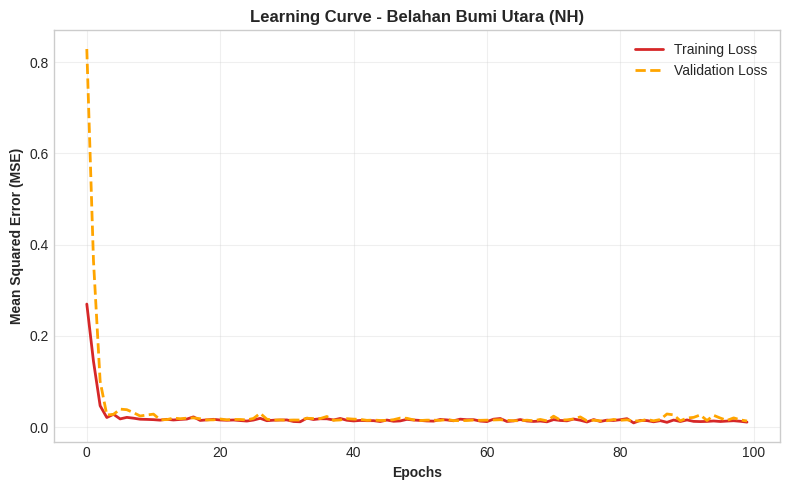

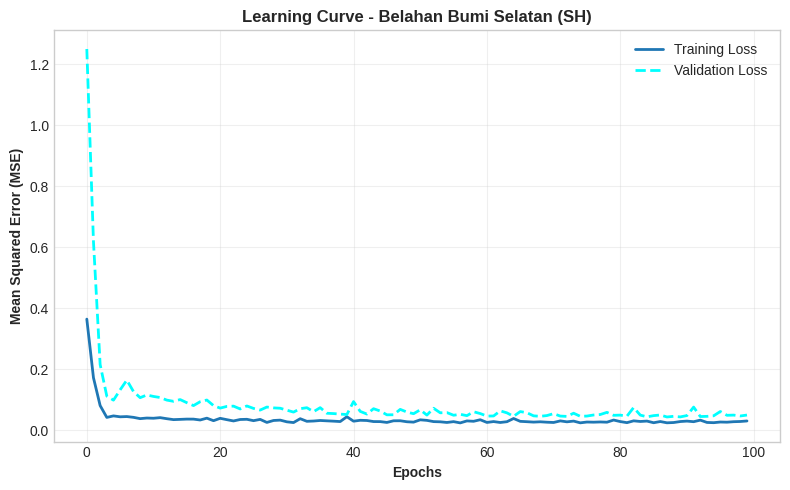

In [5]:
# ==========================================
# TAHAP 9-10: Inisialisasi, Pelatihan LSTM, & Learning Curve
# Membangun arsitektur, melatih model, dan memvalidasi konvergensi
# ==========================================
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import matplotlib.pyplot as plt

# 1. Fungsi Arsitektur Jaringan Multivariate LSTM
def build_lstm_model(input_shape):
    model = Sequential([
        LSTM(units=64, return_sequences=False, input_shape=input_shape),
        Dropout(0.2),
        Dense(units=1)
    ])
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model

# Inisialisasi model untuk Utara (NH) dan Selatan (SH)
# Memori 64 unit, Dropout 20% untuk mencegah overfitting
model_nh = build_lstm_model((SEQ_LENGTH, 2))
model_sh = build_lstm_model((SEQ_LENGTH, 2))

# 2. Pelatihan Model (Training) & Ekstraksi Riwayat (History)
print("Training Model Belahan Bumi Utara (NH)...")
history_nh = model_nh.fit(
    X_train_nh, y_train_nh,
    epochs=100,
    batch_size=4,
    validation_data=(X_test_nh, y_test_nh),
    verbose=0
)
print("Training Model NH Selesai.")

print("Training Model Belahan Bumi Selatan (SH)...")
history_sh = model_sh.fit(
    X_train_sh, y_train_sh,
    epochs=100,
    batch_size=4,
    validation_data=(X_test_sh, y_test_sh),
    verbose=0
)
print("Training Model SH Selesai.")

# 3. Visualisasi Learning Curve (Loss vs Validation Loss)
print("\n--- Menampilkan Grafik Learning Curve ---")

# --- Kurva Pembelajaran Utara (NH) ---
fig_nh, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(history_nh.history['loss'], label='Training Loss', color='tab:red', linewidth=2)
ax1.plot(history_nh.history['val_loss'], label='Validation Loss', color='orange', linewidth=2, linestyle='--')
ax1.set_title('Learning Curve - Belahan Bumi Utara (NH)', fontweight='bold')
ax1.set_xlabel('Epochs', fontweight='bold')
ax1.set_ylabel('Mean Squared Error (MSE)', fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Kurva Pembelajaran Selatan (SH) ---
fig_sh, ax2 = plt.subplots(figsize=(8, 5))
ax2.plot(history_sh.history['loss'], label='Training Loss', color='tab:blue', linewidth=2)
ax2.plot(history_sh.history['val_loss'], label='Validation Loss', color='cyan', linewidth=2, linestyle='--')
ax2.set_title('Learning Curve - Belahan Bumi Selatan (SH)', fontweight='bold')
ax2.set_xlabel('Epochs', fontweight='bold')
ax2.set_ylabel('Mean Squared Error (MSE)', fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

--- Memproses Hasil Prediksi dan Evaluasi Metrik ---
NH - RMSE: 0.1360 °C | MAE: 0.1120 °C
SH - RMSE: 0.0893 °C | MAE: 0.0803 °C


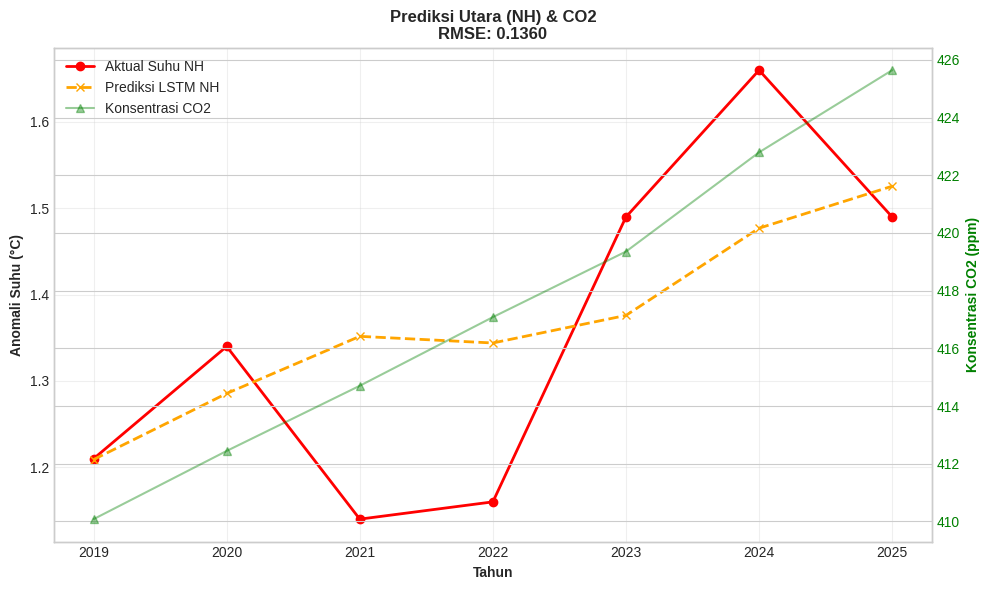

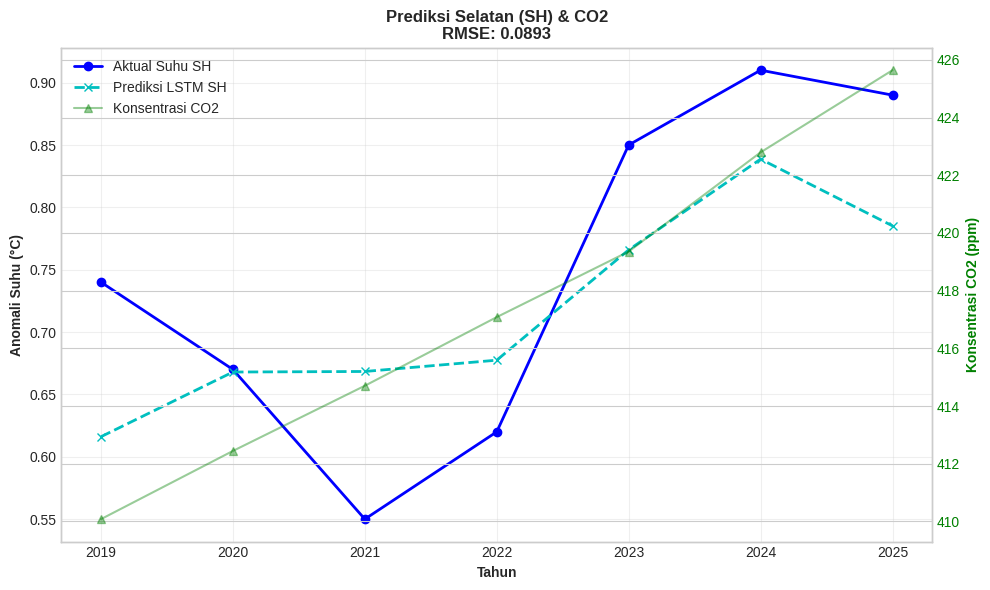

In [6]:
# ==========================================
# TAHAP 11 : Evaluasi RMSE & MAE + Visualisasi Tren CO2
# ==========================================
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import numpy as np

print("--- Memproses Hasil Prediksi dan Evaluasi Metrik ---")

# 1. Prediksi Probabilitas
preds_nh_scaled = model_nh.predict(X_test_nh, verbose=0)
preds_sh_scaled = model_sh.predict(X_test_sh, verbose=0)

# 2. Inverse Transform untuk kembali ke derajat Celcius
def inverse_rescale(scaler, scaled_preds, actual_y):
    dummy_preds = np.zeros((len(scaled_preds), 2))
    dummy_preds[:, 1] = scaled_preds[:, 0]
    dummy_actual = np.zeros((len(actual_y), 2))
    dummy_actual[:, 1] = actual_y
    return scaler.inverse_transform(dummy_preds)[:, 1], scaler.inverse_transform(dummy_actual)[:, 1]

preds_nh, actual_nh = inverse_rescale(scaler_nh, preds_nh_scaled, y_test_nh)
preds_sh, actual_sh = inverse_rescale(scaler_sh, preds_sh_scaled, y_test_sh)

# 3. Perhitungan Metrik Evaluasi
rmse_nh = np.sqrt(mean_squared_error(actual_nh, preds_nh))
mae_nh = mean_absolute_error(actual_nh, preds_nh)
rmse_sh = np.sqrt(mean_squared_error(actual_sh, preds_sh))
mae_sh = mean_absolute_error(actual_sh, preds_sh)

print(f"NH - RMSE: {rmse_nh:.4f} °C | MAE: {mae_nh:.4f} °C")
print(f"SH - RMSE: {rmse_sh:.4f} °C | MAE: {mae_sh:.4f} °C")

# 4. Ekstraksi Tahun dan Data CO2 Aktual untuk Sinkronisasi Sumbu X
test_start_idx = train_size + SEQ_LENGTH
years_test = df_merged['Year'].iloc[test_start_idx:].values
co2_test = df_merged['CO2_ppm'].iloc[test_start_idx:].values

# 5. Visualisasi Hasil Prediksi (Terpisah)

# --- Plot Belahan Bumi Utara (NH) ---
fig_nh, ax1 = plt.subplots(figsize=(10, 6))

# Sumbu Utama (Suhu)
ax1.plot(years_test, actual_nh, 'ro-', label='Aktual Suhu NH', linewidth=2)
ax1.plot(years_test, preds_nh, 'x--', color='orange', label='Prediksi LSTM NH', linewidth=2)
ax1.set_xlabel('Tahun', fontweight='bold')
ax1.set_ylabel('Anomali Suhu (°C)', fontweight='bold')
ax1.set_title(f'Prediksi Utara (NH) & CO2\nRMSE: {rmse_nh:.4f}', fontweight='bold')
ax1.grid(True, alpha=0.3)

# Sumbu Sekunder (CO2)
ax1b = ax1.twinx()
ax1b.plot(years_test, co2_test, 'g^-', alpha=0.4, label='Konsentrasi CO2')
ax1b.set_ylabel('Konsentrasi CO2 (ppm)', color='green', fontweight='bold')
ax1b.tick_params(axis='y', labelcolor='green')

# Gabung Legenda NH
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_1b, labels_1b = ax1b.get_legend_handles_labels()
ax1b.legend(lines_1 + lines_1b, labels_1 + labels_1b, loc='upper left')

plt.tight_layout()
plt.show()


# --- Plot Belahan Bumi Selatan (SH) ---
fig_sh, ax2 = plt.subplots(figsize=(10, 6))

# Sumbu Utama (Suhu)
ax2.plot(years_test, actual_sh, 'bo-', label='Aktual Suhu SH', linewidth=2)
ax2.plot(years_test, preds_sh, 'cx--', label='Prediksi LSTM SH', linewidth=2)
ax2.set_xlabel('Tahun', fontweight='bold')
ax2.set_ylabel('Anomali Suhu (°C)', fontweight='bold')
ax2.set_title(f'Prediksi Selatan (SH) & CO2\nRMSE: {rmse_sh:.4f}', fontweight='bold')
ax2.grid(True, alpha=0.3)

# Sumbu Sekunder (CO2)
ax2b = ax2.twinx()
ax2b.plot(years_test, co2_test, 'g^-', alpha=0.4, label='Konsentrasi CO2')
ax2b.set_ylabel('Konsentrasi CO2 (ppm)', color='green', fontweight='bold')
ax2b.tick_params(axis='y', labelcolor='green')

# Gabung Legenda SH
lines_2, labels_2 = ax2.get_legend_handles_labels()
lines_2b, labels_2b = ax2b.get_legend_handles_labels()
ax2b.legend(lines_2 + lines_2b, labels_2 + labels_2b, loc='upper left')

plt.tight_layout()
plt.show()

--- Memulai Ekstraksi SHAP Values ---
Menghitung SHAP Values NH (Mohon tunggu, proses ini memakan waktu komputasi)...


  0%|          | 0/7 [00:00<?, ?it/s]

Menghitung SHAP Values SH...


  0%|          | 0/7 [00:00<?, ?it/s]


[Visualisasi SHAP: Belahan Bumi Utara]


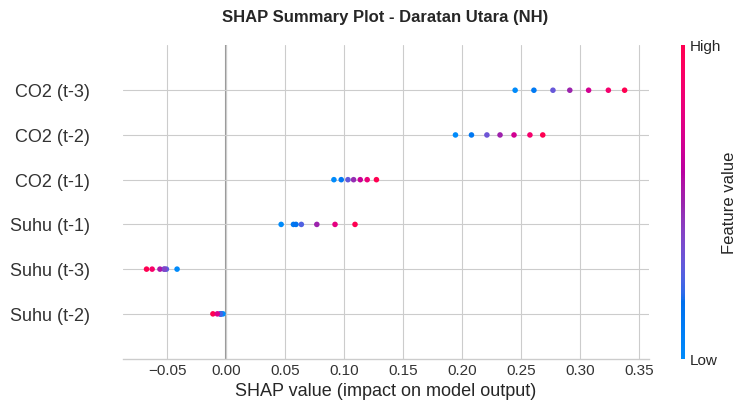


[Visualisasi SHAP: Belahan Bumi Selatan]


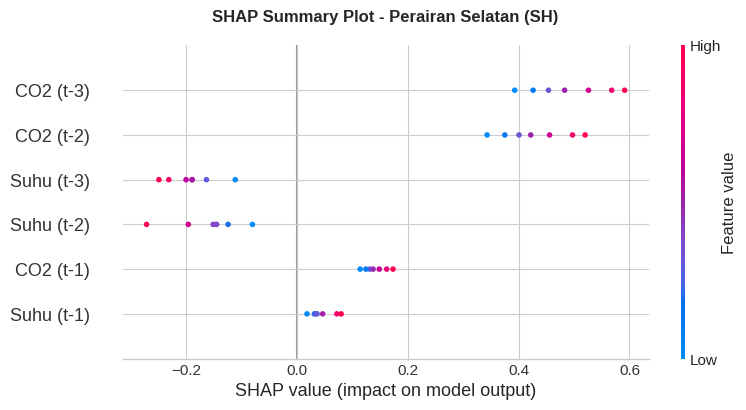

In [7]:
# ==========================================
# TAHAP 12: EXPLAINABLE AI (XAI) MENGGUNAKAN SHAP
# ==========================================
import shap
import numpy as np
import matplotlib.pyplot as plt

print("--- Memulai Ekstraksi SHAP Values ---")

# 1. Fungsi Wrapper Agnostik (Menjembatani 2D SHAP dan 3D LSTM)
def model_predict_nh(data_2d):
    # Mengembalikan data 2D ke format 3D (Samples, SEQ_LENGTH, Features) untuk LSTM
    data_3d = data_2d.reshape(data_2d.shape[0], SEQ_LENGTH, 2)
    return model_nh.predict(data_3d, verbose=0).flatten()

def model_predict_sh(data_2d):
    data_3d = data_2d.reshape(data_2d.shape[0], SEQ_LENGTH, 2)
    return model_sh.predict(data_3d, verbose=0).flatten()

# 2. Meratakan Dimensi Data (Flattening) untuk SHAP KernelExplainer
X_train_nh_2d = X_train_nh.reshape(X_train_nh.shape[0], SEQ_LENGTH * 2)
X_test_nh_2d = X_test_nh.reshape(X_test_nh.shape[0], SEQ_LENGTH * 2)

X_train_sh_2d = X_train_sh.reshape(X_train_sh.shape[0], SEQ_LENGTH * 2)
X_test_sh_2d = X_test_sh.reshape(X_test_sh.shape[0], SEQ_LENGTH * 2)

# 3. K-Means Background Aggregation (Peringkas Data untuk Komputasi)
background_nh = shap.kmeans(X_train_nh_2d, 10)
background_sh = shap.kmeans(X_train_sh_2d, 10)

# 4. Inisialisasi KernelExplainer
explainer_nh = shap.KernelExplainer(model_predict_nh, background_nh)
explainer_sh = shap.KernelExplainer(model_predict_sh, background_sh)

# Menghitung SHAP values pada data uji (Testing Set)
print("Menghitung SHAP Values NH (Mohon tunggu, proses ini memakan waktu komputasi)...")
shap_values_nh = explainer_nh.shap_values(X_test_nh_2d)

print("Menghitung SHAP Values SH...")
shap_values_sh = explainer_sh.shap_values(X_test_sh_2d)

# 5. Pembuatan Label Fitur berdasarkan Sliding Window
# Format: [CO2(t-3), Suhu(t-3), CO2(t-2), Suhu(t-2), CO2(t-1), Suhu(t-1)]
feature_names = [f'CO2 (t-{SEQ_LENGTH-i})' if j==0 else f'Suhu (t-{SEQ_LENGTH-i})'
                 for i in range(SEQ_LENGTH) for j in range(2)]

# 6. Visualisasi SHAP Summary Plot
print("\n[Visualisasi SHAP: Belahan Bumi Utara]")
plt.figure()
shap.summary_plot(shap_values_nh, X_test_nh_2d, feature_names=feature_names, show=False)
plt.title("SHAP Summary Plot - Daratan Utara (NH)", fontweight='bold', y=1.05)
plt.show()

print("\n[Visualisasi SHAP: Belahan Bumi Selatan]")
plt.figure()
shap.summary_plot(shap_values_sh, X_test_sh_2d, feature_names=feature_names, show=False)
plt.title("SHAP Summary Plot - Perairan Selatan (SH)", fontweight='bold', y=1.05)
plt.show()

In [8]:
# ==========================================
# TAHAP 13 : PREDIKSI CO2 & SUHU (FULL LSTM)
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

print("--- 1. Melatih Model LSTM Khusus untuk CO2 ---")

# A. Persiapan Data CO2 (Univariate)
scaler_co2 = MinMaxScaler(feature_range=(0, 1))
scaler_co2.fit(df_merged[['CO2_ppm']].iloc[:train_size])
data_co2 = scaler_co2.transform(df_merged[['CO2_ppm']])

# Ekstraksi Sliding Window untuk CO2
def create_sequences_1d(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:(i + seq_length)])
        y.append(data[i + seq_length, 0])
    return np.array(X), np.array(y)

X_co2, y_co2 = create_sequences_1d(data_co2, SEQ_LENGTH)
X_train_co2, X_test_co2 = X_co2[:train_size], X_co2[train_size:]
y_train_co2, y_test_co2 = y_co2[:train_size], y_co2[train_size:]

# B. Membangun dan Melatih Model LSTM CO2 (Disamakan dengan arsitektur suhu)
model_co2 = Sequential([
    LSTM(units=64, return_sequences=False, input_shape=(SEQ_LENGTH, 1)),
    Dropout(0.2),
    Dense(units=1)
])
model_co2.compile(optimizer='adam', loss='mean_squared_error')

print("Training Model CO2 (mohon tunggu)...")
model_co2.fit(X_train_co2, y_train_co2, epochs=100, batch_size=4,
              validation_data=(X_test_co2, y_test_co2), verbose=0)
print("Training Model CO2 Selesai.")

print("\n--- 2. Melakukan Prediksi (Forecasting) 10 Tahun Kedepan ---")

langkah_10_tahun = 10
tahun_terakhir_data = df_merged['Year'].max()

# A. Fungsi Prediksi CO2 (Univariate)
def predict_future_co2(model, initial_sequence, steps):
    future_preds_scaled = []
    current_seq = initial_sequence.copy()
    for _ in range(steps):
        input_3d = current_seq.reshape(1, SEQ_LENGTH, 1)
        pred_scaled = model.predict(input_3d, verbose=0)[0][0]
        future_preds_scaled.append(pred_scaled)
        current_seq = np.append(current_seq[1:], [[pred_scaled]], axis=0)
    return future_preds_scaled

# Prediksi CO2
last_sequence_co2 = X_test_co2[-1]
preds_future_co2_scaled = predict_future_co2(model_co2, last_sequence_co2, langkah_10_tahun)

# B. Fungsi Prediksi Suhu menggunakan Prediksi CO2 LSTM (Multivariate)
def predict_future_temp_with_lstm_co2(model_temp, initial_sequence_temp, future_co2_scaled, steps):
    future_preds_temp_scaled = []
    current_seq = initial_sequence_temp.copy()
    for i in range(steps):
        input_3d = current_seq.reshape(1, SEQ_LENGTH, 2)
        pred_suhu_scaled = model_temp.predict(input_3d, verbose=0)[0][0]
        future_preds_temp_scaled.append(pred_suhu_scaled)

        # Gunakan nilai CO2 hasil prediksi LSTM sebelumnya
        co2_scaled = future_co2_scaled[i]
        new_row = np.array([co2_scaled, pred_suhu_scaled])
        current_seq = np.vstack((current_seq[1:], new_row))
    return future_preds_temp_scaled

# Prediksi Suhu NH dan SH
last_sequence_nh = X_test_nh[-1]
last_sequence_sh = X_test_sh[-1]
preds_future_nh_scaled = predict_future_temp_with_lstm_co2(model_nh, last_sequence_nh, preds_future_co2_scaled, langkah_10_tahun)
preds_future_sh_scaled = predict_future_temp_with_lstm_co2(model_sh, last_sequence_sh, preds_future_co2_scaled, langkah_10_tahun)

# C. Kembalikan Skala (Inverse Transform)
preds_future_co2 = scaler_co2.inverse_transform(np.array(preds_future_co2_scaled).reshape(-1, 1)).flatten()

def inverse_temp(scaler, future_preds_scaled):
    dummy_preds = np.zeros((len(future_preds_scaled), 2))
    dummy_preds[:, 1] = future_preds_scaled
    return scaler.inverse_transform(dummy_preds)[:, 1]

preds_future_nh = inverse_temp(scaler_nh, preds_future_nh_scaled)
preds_future_sh = inverse_temp(scaler_sh, preds_future_sh_scaled)

# ==========================================
# Menyusun DataFrame Hasil Prediksi (Mulai 2027)
# ==========================================
tahun_awal_prediksi = 2027
tahun_masa_depan = np.arange(tahun_awal_prediksi, tahun_awal_prediksi + langkah_10_tahun)

df_pred_masa_depan = pd.DataFrame({
    'Tahun': tahun_masa_depan,
    'Prediksi_CO2_ppm': preds_future_co2,
    'Prediksi_Suhu_NH': preds_future_nh,
    'Prediksi_Suhu_SH': preds_future_sh
})

print("\n=== Tabel Prediksi 5 Tahun Kedepan (2027-2031) ===")
print(df_pred_masa_depan.head(5).to_string(index=False))

print("\n=== Tabel Prediksi 10 Tahun Kedepan (2027-2036) ===")
print(df_pred_masa_depan.to_string(index=False))

--- 1. Melatih Model LSTM Khusus untuk CO2 ---
Training Model CO2 (mohon tunggu)...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training Model CO2 Selesai.

--- 2. Melakukan Prediksi (Forecasting) 10 Tahun Kedepan ---

=== Tabel Prediksi 5 Tahun Kedepan (2027-2031) ===
 Tahun  Prediksi_CO2_ppm  Prediksi_Suhu_NH  Prediksi_Suhu_SH
  2027        429.206757          1.525619          0.785161
  2028        433.066376          1.518672          0.714957
  2029        438.311707          1.576805          0.780493
  2030        444.375031          1.685788          0.920933
  2031        449.696838          1.772966          1.005758

=== Tabel Prediksi 10 Tahun Kedepan (2027-2036) ===
 Tahun  Prediksi_CO2_ppm  Prediksi_Suhu_NH  Prediksi_Suhu_SH
  2027        429.206757          1.525619          0.785161
  2028        433.066376          1.518672          0.714957
  2029        438.311707          1.576805          0.780493
  2030        444.375031          1.685788          0.920933
  2031        449.696838          1.772966          1.005758
  2032        455.911957          1.858767          1.023294
  2033      


--- Menampilkan Grafik Proyeksi (Khusus Masa Depan) ---

[Grafik 5 Tahun Kedepan: 2027 - 2031]


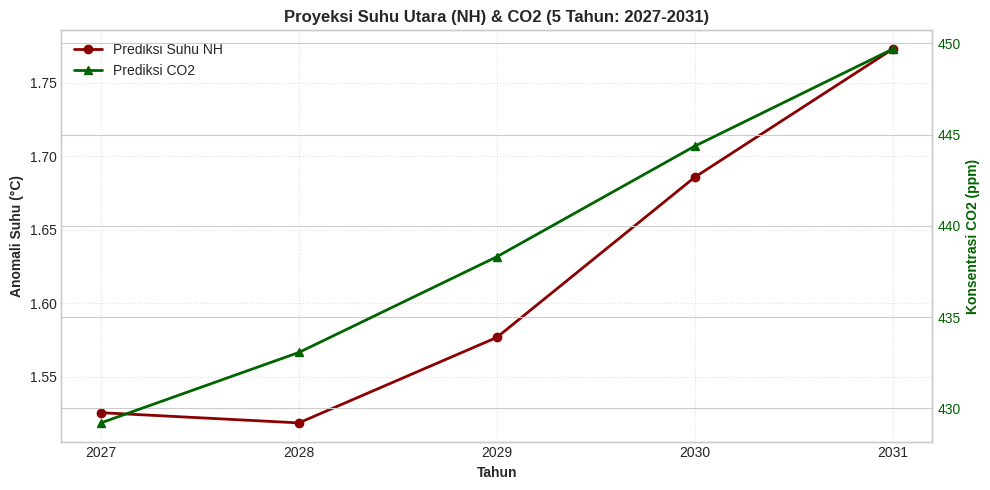

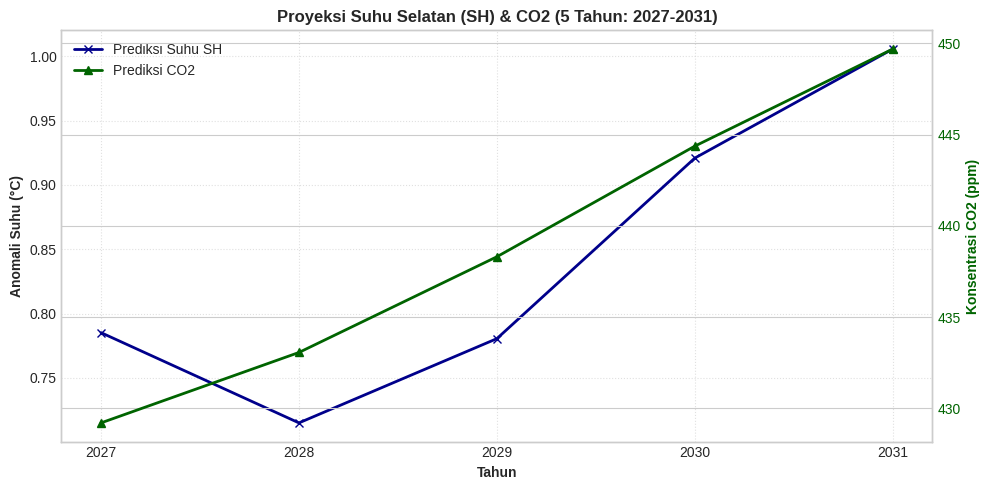


[Grafik 10 Tahun Kedepan: 2027 - 2036]


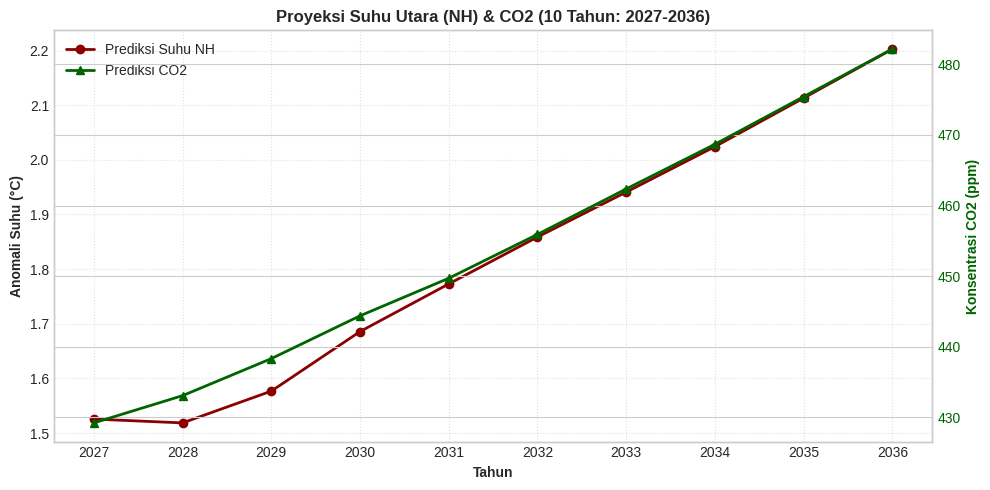

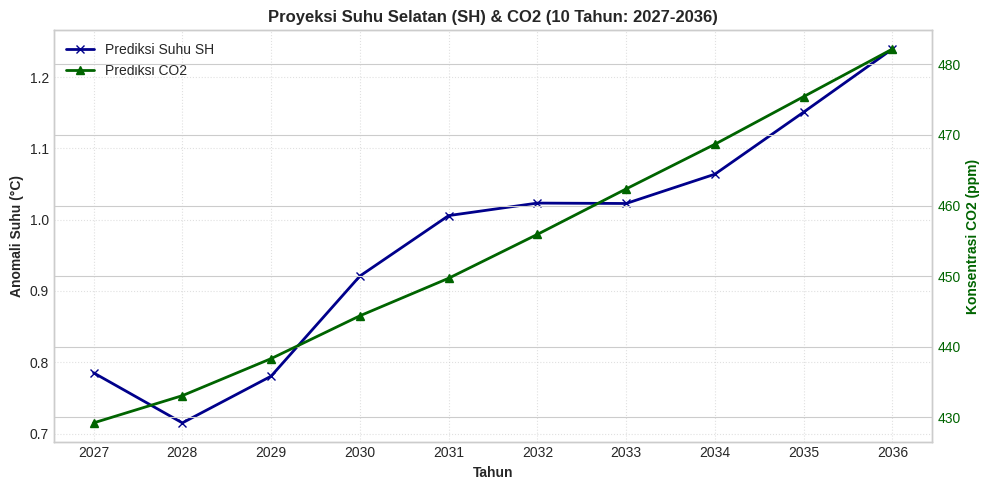

In [9]:
# ==========================================
# 3. Visualisasi Hasil (Dipisah Utara dan Selatan)
# ==========================================
print("\n--- Menampilkan Grafik Proyeksi (Khusus Masa Depan) ---")

# Mengambil dataframe khusus 5 tahun (2027-2031)
df_pred_5_tahun = df_pred_masa_depan.head(5)
df_pred_10_tahun = df_pred_masa_depan # (2027-2036)

# Fungsi plot untuk satu belahan bumi
def plot_terpisah(df_plot, belahan, judul, warna_suhu, marker_suhu):
    fig, ax1 = plt.subplots(figsize=(10, 5))

    # Plot Suhu (Kiri)
    nama_kolom_suhu = f'Prediksi_Suhu_{belahan}'
    label_suhu = f'Prediksi Suhu {belahan}'

    ax1.plot(df_plot['Tahun'], df_plot[nama_kolom_suhu], label=label_suhu, color=warna_suhu, linestyle='-', marker=marker_suhu, linewidth=2)

    # Memaksa sumbu X menampilkan angka tahun dengan tepat (tanpa desimal)
    ax1.set_xticks(df_plot['Tahun'])

    ax1.set_xlabel('Tahun', fontweight='bold')
    ax1.set_ylabel('Anomali Suhu (°C)', fontweight='bold')
    ax1.grid(True, linestyle=':', alpha=0.6)

    # Plot CO2 (Kanan)
    ax2 = ax1.twinx()
    ax2.plot(df_plot['Tahun'], df_plot['Prediksi_CO2_ppm'], label='Prediksi CO2', color='darkgreen', linestyle='-', marker='^', linewidth=2)
    ax2.set_ylabel('Konsentrasi CO2 (ppm)', color='darkgreen', fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='darkgreen')

    # Gabung Legenda
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

    plt.title(judul, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ==========================================
# GRAFIK 5 TAHUN KEDEPAN (2027 - 2031)
# ==========================================
print("\n[Grafik 5 Tahun Kedepan: 2027 - 2031]")
plot_terpisah(df_pred_5_tahun, 'NH', 'Proyeksi Suhu Utara (NH) & CO2 (5 Tahun: 2027-2031)', 'darkred', 'o')
plot_terpisah(df_pred_5_tahun, 'SH', 'Proyeksi Suhu Selatan (SH) & CO2 (5 Tahun: 2027-2031)', 'darkblue', 'x')

# ==========================================
# GRAFIK 10 TAHUN KEDEPAN (2027 - 2036)
# ==========================================
print("\n[Grafik 10 Tahun Kedepan: 2027 - 2036]")
plot_terpisah(df_pred_10_tahun, 'NH', 'Proyeksi Suhu Utara (NH) & CO2 (10 Tahun: 2027-2036)', 'darkred', 'o')
plot_terpisah(df_pred_10_tahun, 'SH', 'Proyeksi Suhu Selatan (SH) & CO2 (10 Tahun: 2027-2036)', 'darkblue', 'x')